In [1]:
from google.colab import files
uploaded = files.upload()

Saving Unemployment in India.csv to Unemployment in India.csv


In [2]:
import pandas as pd

df = pd.read_csv("Unemployment in India.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset loaded successfully!
Dataset Shape: (768, 7)

First 5 Rows:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural



Column Names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB


In [3]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values in Each Column:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

Total Missing Values:
196

Duplicate Rows:
27


In [4]:
print("Completely Empty Rows:")
print(df.isnull().all(axis=1).sum())

print("\nRows Containing Missing Values:")
display(df[df.isnull().any(axis=1)].head(10))

Completely Empty Rows:
28

Rows Containing Missing Values:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
359,NaN,NaN,NaN,NaN,NaN,NaN,NaN
360,NaN,NaN,NaN,NaN,NaN,NaN,NaN
361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
363,NaN,NaN,NaN,NaN,NaN,NaN,NaN
364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
365,NaN,NaN,NaN,NaN,NaN,NaN,NaN
366,NaN,NaN,NaN,NaN,NaN,NaN,NaN
367,NaN,NaN,NaN,NaN,NaN,NaN,NaN
368,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Remove completely empty rows
df = df.dropna(how='all')

# Remove duplicate records
df = df.drop_duplicates()

# Check the cleaned dataset
print("Dataset cleaned successfully!")

print("New Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset cleaned successfully!
New Dataset Shape: (740, 7)

Missing Values:
Region                                      0
 Date                                       0
 Frequency                                  0
 Estimated Unemployment Rate (%)            0
 Estimated Employed                         0
 Estimated Labour Participation Rate (%)    0
Area                                        0
dtype: int64

Duplicate Rows:
0


In [6]:
# Fill missing numerical values with median
for col in df.select_dtypes(include='number').columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with mode
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values after cleaning:
Region                                      0
 Date                                       0
 Frequency                                  0
 Estimated Unemployment Rate (%)            0
 Estimated Employed                         0
 Estimated Labour Participation Rate (%)    0
Area                                        0
dtype: int64

Total missing values: 0


In [9]:
# Convert Date column into datetime format
df['Date'] = pd.to_datetime(df['Date'].str.strip(), dayfirst=True)

# Sort data by date
df = df.sort_values(by='Date')

print("Date conversion completed!")
print(df[['Date', 'Region']].head())

print("\nDate Range:")
print("Start Date:", df['Date'].min())
print("End Date:", df['Date'].max())

Date conversion completed!
          Date          Region
0   2019-05-31  Andhra Pradesh
290 2019-05-31       Telangana
276 2019-05-31      Tamil Nadu
257 2019-05-31       Rajasthan
243 2019-05-31          Punjab

Date Range:
Start Date: 2019-05-31 00:00:00
End Date: 2020-06-30 00:00:00


In [8]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Display column names
print("Available columns:")
print(df.columns.tolist())

Available columns:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']


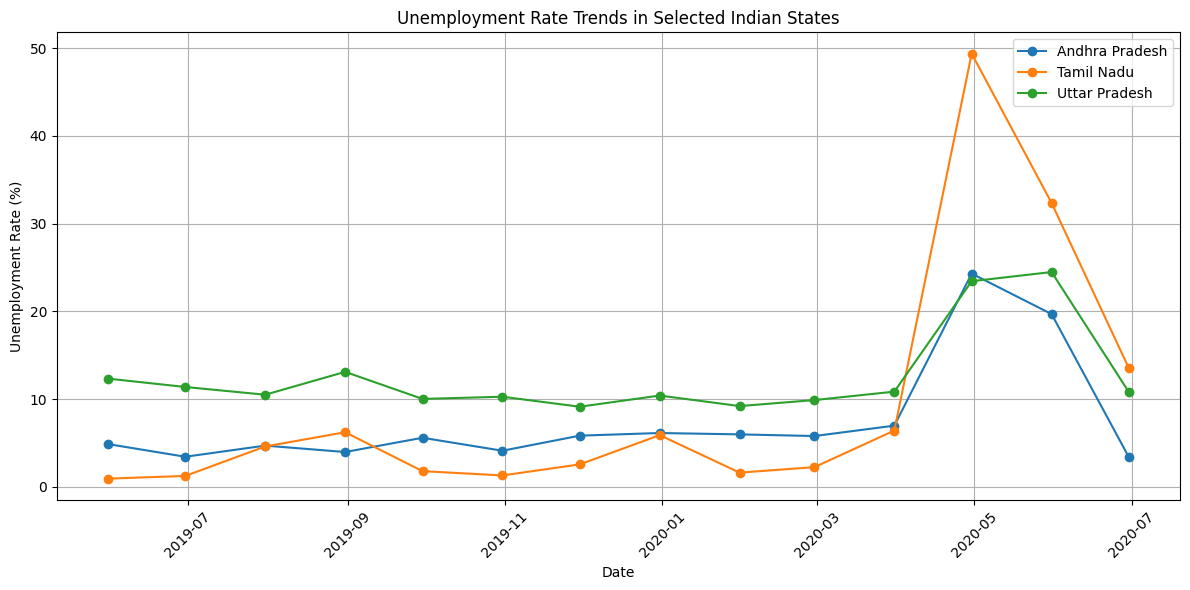

In [10]:
import matplotlib.pyplot as plt

# Select three major states
states = ['Andhra Pradesh', 'Tamil Nadu', 'Uttar Pradesh']

# Calculate average unemployment rate by date and state
trend = df[df['Region'].isin(states)].groupby(
    ['Date', 'Region']
)['Estimated Unemployment Rate (%)'].mean().reset_index()

# Plot line chart
plt.figure(figsize=(12, 6))

for state in states:
    state_data = trend[trend['Region'] == state]
    plt.plot(
        state_data['Date'],
        state_data['Estimated Unemployment Rate (%)'],
        marker='o',
        label=state
    )

plt.title('Unemployment Rate Trends in Selected Indian States')
plt.xlabel('Date')
plt.ylabel('Unemployment Rate (%)')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

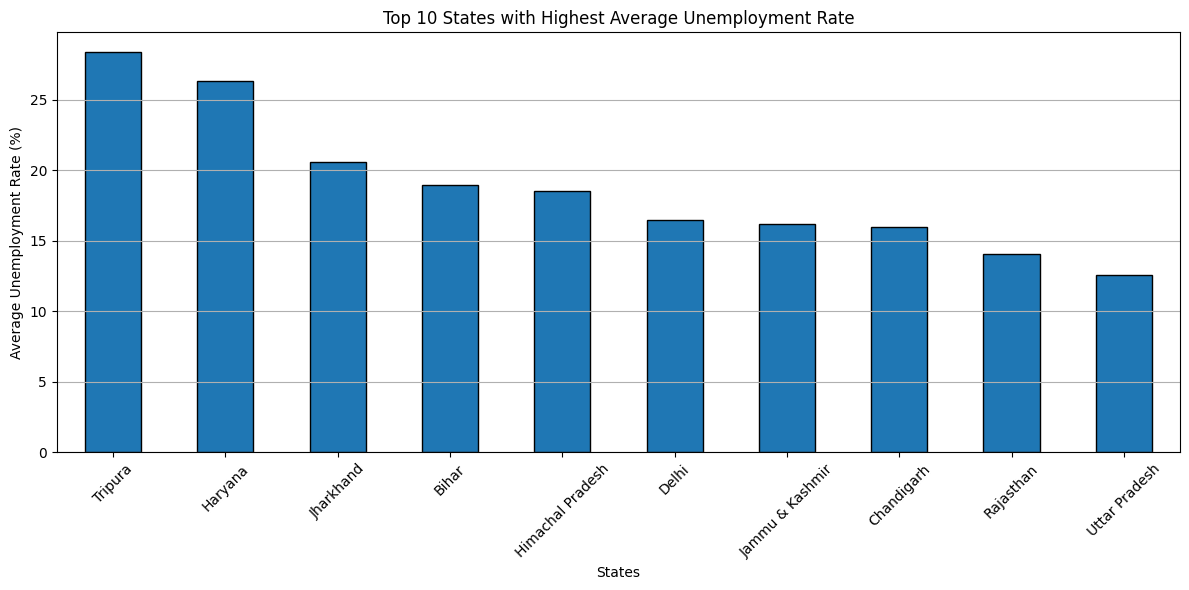

In [11]:
import matplotlib.pyplot as plt

# Calculate average unemployment rate for each state
state_avg = df.groupby('Region')[
    'Estimated Unemployment Rate (%)'
].mean().sort_values(ascending=False)

# Select top 10 states
top_10 = state_avg.head(10)

# Create bar chart
plt.figure(figsize=(12, 6))
top_10.plot(kind='bar', edgecolor='black')

plt.title('Top 10 States with Highest Average Unemployment Rate')
plt.xlabel('States')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

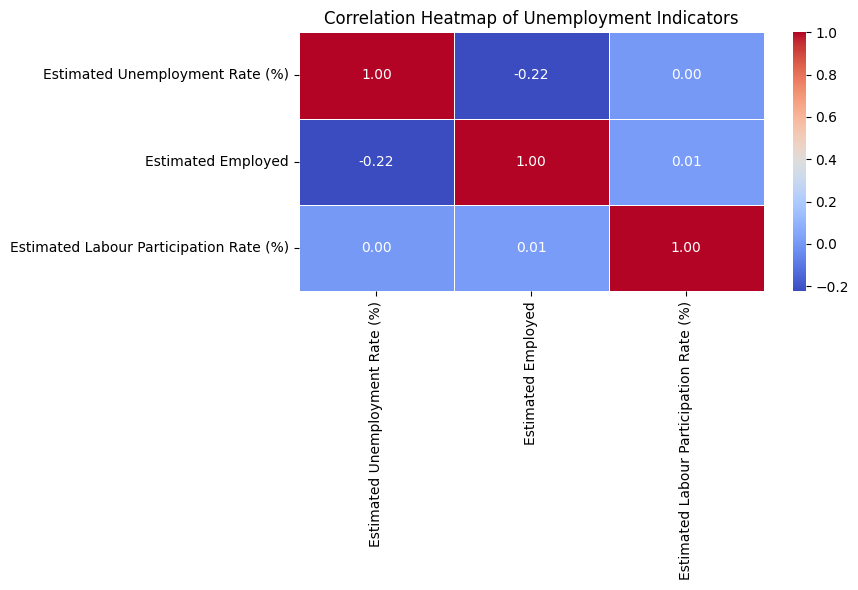

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select important numerical columns
correlation_data = df[[
    'Estimated Unemployment Rate (%)',
    'Estimated Employed',
    'Estimated Labour Participation Rate (%)'
]]

# Calculate correlation
correlation_matrix = correlation_data.corr()

# Create heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Unemployment Indicators')
plt.tight_layout()
plt.show()

Pre-COVID vs Post-COVID Average Unemployment Rate:
Period
Post-COVID    17.774363
Pre-COVID      9.509534
Name: Estimated Unemployment Rate (%), dtype: float64


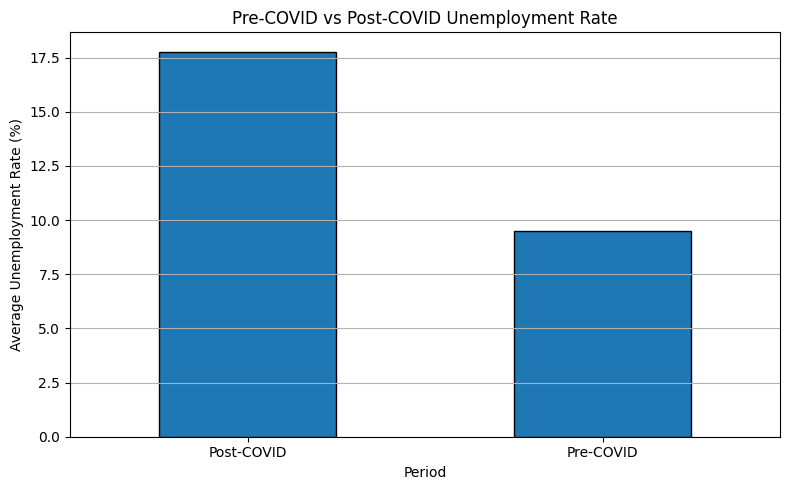

In [13]:
import matplotlib.pyplot as plt

# Divide data into pre-COVID and post-COVID periods
df['Period'] = df['Date'].apply(
    lambda x: 'Pre-COVID' if x < pd.Timestamp('2020-03-01')
    else 'Post-COVID'
)

# Calculate average unemployment rate
covid_comparison = df.groupby('Period')[
    'Estimated Unemployment Rate (%)'
].mean()

print("Pre-COVID vs Post-COVID Average Unemployment Rate:")
print(covid_comparison)

# Create comparison chart
plt.figure(figsize=(8, 5))
covid_comparison.plot(kind='bar', edgecolor='black')

plt.title('Pre-COVID vs Post-COVID Unemployment Rate')
plt.xlabel('Period')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

## Observations and Findings

1. The unemployment rate varied across different Indian states during the study period.
2. Tamil Nadu experienced a sharp increase in unemployment around May 2020.
3. The top 10 states analysis identifies regions with higher average unemployment rates.
4. The correlation heatmap shows relationships between unemployment, employment and labour participation indicators.
5. The pre-COVID and post-COVID comparison shows changes in average unemployment rates during the selected periods.

## Conclusion

This project analyzed unemployment trends in India using Python. Data cleaning, exploratory data analysis and visualization techniques were used to understand regional differences and changes over time. The analysis highlights variations in unemployment rates and provides insights into the employment situation during the COVID-19 period.